Dieses Notebook trägt die mathematischen und physikalischen Grundlagen zum Verständnis der Wellenfunktion zusammen. Los geht es mit dem Enheitskreis, um die mathematische Darstellung von Wellen zu erarbeiten.

# Kapitel 1: Trigonometrie

## 1.1 Der Einheitskreis

Ein Einheitskreis besitzt den Radius 1.

Ein Punkt auf dem Kreis hat die Koordinaten:

$$P(\varphi)=(\cos\varphi,\sin\varphi)$$

Dabei gilt:

$$\sin^2(\varphi)+\cos^2(\varphi)=1$$

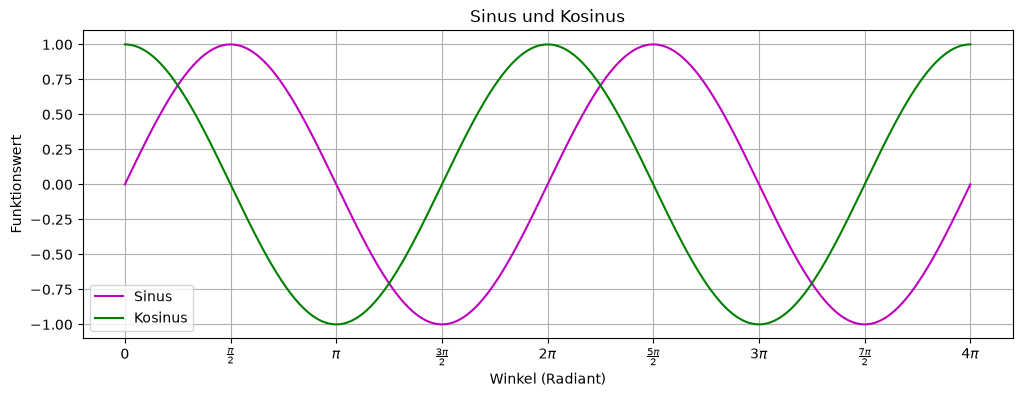

In [123]:

import numpy as np
import matplotlib.pyplot as plt

phi = np.linspace(0, 4*np.pi, 500)

sinus = np.sin(phi)
kosinus = np.cos(phi)

plt.figure(figsize=(12, 4))

plt.plot(phi, sinus, 'm-', label="Sinus")
plt.plot(phi, kosinus, 'g-', label="Kosinus")
plt.xticks(
    [0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi,
     5*np.pi/2, 3*np.pi, 7*np.pi/2, 4*np.pi],
    ['0', r'$\frac{\pi}{2}$', r'$\pi$',
     r'$\frac{3\pi}{2}$', r'$2\pi$',
     r'$\frac{5\pi}{2}$', r'$3\pi$',
     r'$\frac{7\pi}{2}$', r'$4\pi$']
)

plt.xlabel("Winkel (Radiant)")
plt.ylabel("Funktionswert")
plt.title("Sinus und Kosinus")

plt.grid(True)
plt.legend()
plt.show()

In [1]:
matplotlib widget

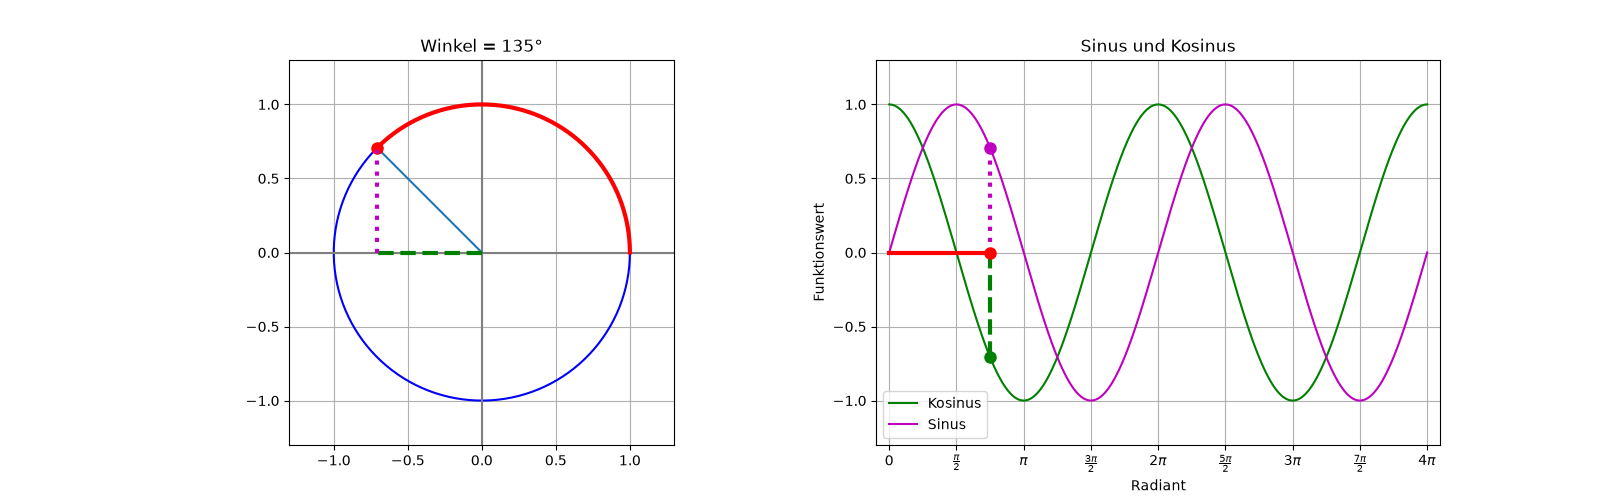

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# Figure einmal erstellen
fig, (ax, ax_sin_cos) = plt.subplots(1, 2, figsize=(16, 5))

t = np.linspace(0, 2*np.pi, 400)
sin_cos_x = np.linspace(0, 4*np.pi, 500)

# Einheitskreis
ax.plot(np.cos(t), np.sin(t), 'b-')
ax.axhline(0, color='gray')
ax.axvline(0, color='gray')

# Dynamische Elemente einmal erstellen
radius, = ax.plot([], [], '-')
punkt, = ax.plot([], [], 'ro', markersize=8)
sin_linie, = ax.plot([], [], 'g--', linewidth=3)
cos_linie, = ax.plot([], [], 'm:', linewidth=3)
bogen_rot, = ax.plot([], [], 'r-', linewidth=3)
bogen_orange, = ax.plot([], [], color='orange', linewidth=3)

ax.set_aspect('equal')
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.grid(True)

# Sinus und Kosinus
ax_sin_cos.plot(sin_cos_x, np.cos(sin_cos_x), 'g-', label="Kosinus")
ax_sin_cos.plot(sin_cos_x, np.sin(sin_cos_x), 'm-', label="Sinus")

cos_punkt, = ax_sin_cos.plot([], [], 'go', markersize=8)
sin_punkt, = ax_sin_cos.plot([], [], 'mo', markersize=8)
cos_hilfe, = ax_sin_cos.plot([], [], 'g--', linewidth=3)
sin_hilfe, = ax_sin_cos.plot([], [], 'm:', linewidth=3)

winkel_rot, = ax_sin_cos.plot([], [], 'r-', linewidth=3)
winkel_orange, = ax_sin_cos.plot([], [], color='orange', linewidth=3)
winkel_punkt, = ax_sin_cos.plot([], [], 'ro', markersize=8)

ticks = np.arange(0, 4*np.pi + 0.01, np.pi/2)
labels = [
    '0', r'$\frac{\pi}{2}$', r'$\pi$',
    r'$\frac{3\pi}{2}$', r'$2\pi$',
    r'$\frac{5\pi}{2}$', r'$3\pi$',
    r'$\frac{7\pi}{2}$', r'$4\pi$'
]

ax_sin_cos.set_xticks(ticks, labels=labels)
ax_sin_cos.set_xlim(-0.3, 4*np.pi + 0.3)
ax_sin_cos.set_ylim(-1.3, 1.3)
ax_sin_cos.set_xlabel("Radiant")
ax_sin_cos.set_ylabel("Funktionswert")
ax_sin_cos.set_title("Sinus und Kosinus")
ax_sin_cos.grid(True)
ax_sin_cos.legend()

# Werteanzeige
werte = widgets.HTML()

def zeichne(winkel):
    phi = np.deg2rad(winkel)
    x = np.cos(phi)
    y = np.sin(phi)

    rad_bog = min(phi, 2*np.pi)
    bog = np.linspace(0, rad_bog, 400)

    # Einheitskreis aktualisieren
    radius.set_data([0, x], [0, y])
    punkt.set_data([x], [y])
    sin_linie.set_data([0, x], [0, 0])
    cos_linie.set_data([x, x], [0, y])
    bogen_rot.set_data(np.cos(bog), np.sin(bog))

    if winkel > 360:
        rad_sec = phi - 2*np.pi
        bog_sec = np.linspace(0, rad_sec, 400)
        bogen_orange.set_data(np.cos(bog_sec), np.sin(bog_sec))
        punkt.set_color('orange')
        winkel_punkt.set_color('orange')
    else:
        bogen_orange.set_data([], [])
        punkt.set_color('red')
        winkel_punkt.set_color('red')

    # Sinus-/Kosinus-Plot aktualisieren
    cos_punkt.set_data([phi], [x])
    sin_punkt.set_data([phi], [y])

    cos_hilfe.set_data([phi, phi], [0, x])
    sin_hilfe.set_data([phi, phi], [0, y])

    winkel_rot.set_data([0, rad_bog], [0, 0])

    if winkel > 360:
        winkel_orange.set_data([2*np.pi, phi], [0, 0])
    else:
        winkel_orange.set_data([], [])

    winkel_punkt.set_data([phi], [0])

    ax.set_title(f"Winkel = {winkel}°")

    werte.value = (
        f"<b>sin:</b> {y:.5f} &nbsp;&nbsp;"
        f"<b>cos:</b> {x:.5f} &nbsp;&nbsp;"
        f"<b>Radiant:</b> {phi:.5f} rad"
    )

    fig.canvas.draw_idle()

regler = widgets.IntSlider(
    value=135,
    min=0,
    max=720,
    step=5,
    description="Winkel:",
    continuous_update=True
)

widgets.interactive_output(zeichne, {"winkel": regler})

display(widgets.VBox([regler, werte]))
plt.show()